In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [13]:
df = pd.read_csv("../results/timings.csv")
e1 = df[(df.experiment == "E1_build_memory") & (df.machine_id == "vivian-mbp")].copy()
print(e1.code_version.unique())

e1 = e1[e1.code_version == "3c5068c"]
e1["ns_per_key"] = e1.total_ns / e1.n_ops
print(len(e1))
print(e1.groupby(["index_type", "n_keys"]).ns_per_key.median().unstack(0))

<StringArray>
['af79e03', '3c5068c']
Length: 2, dtype: str
245
index_type     avl_tree   bplus_tree   hash_table   ref_bisect    ref_dict  \
n_keys                                                                       
1000        4979.334000  1709.958000  1071.833000    627.58300  231.833000   
2000        5540.854000  1905.458500  1063.187500    774.22900  232.167000   
5000        6001.308400  2101.683200   971.458200   1024.70840  205.575000   
10000       6513.512500  2185.383300   988.604100   1694.84580  196.504200   
20000       7038.837500  2289.550000  1009.547950   3205.21040  210.618750   
50000       7691.727500  2666.222500  1068.304160   6986.83834  240.634160   
114000      8335.429465  3043.836623  1191.800807  12486.25000  268.453588   

index_type   sorted_list  unsorted_list  
n_keys                                   
1000         1434.667000     146.542000  
2000         1681.020500     168.479000  
5000         2171.341600     151.241600  
10000        2864.233400

           index  slope
0       avl_tree   1.11
1     bplus_tree   1.11
2     hash_table   1.02
3     ref_bisect   1.66
4       ref_dict   1.03
5    sorted_list   1.49
6  unsorted_list   0.97


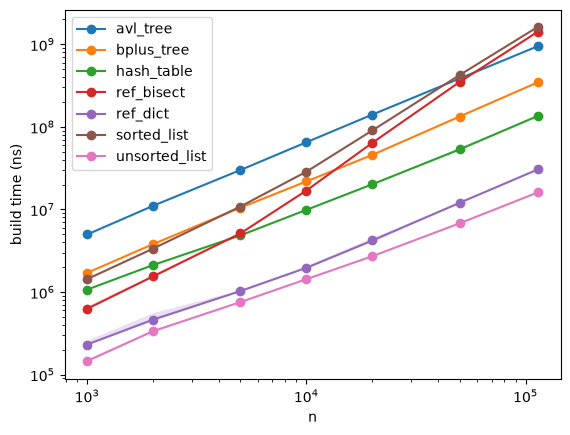

index_type
avl_tree         115.2
bplus_tree        80.3
hash_table       195.3
ref_bisect        72.6
ref_dict          92.3
sorted_list       72.6
unsorted_list     64.9
Name: memory_bytes, dtype: float64


In [14]:
# log-log slope of total build time vs n, per index
rows = []
for name, g in e1.groupby("index_type"):
    med = g.groupby("n_keys").total_ns.median()
    slope = np.polyfit(np.log(med.index), np.log(med.values), 1)[0]
    rows.append((name, round(slope, 2)))
print(pd.DataFrame(rows, columns=["index", "slope"]))

# median with IQR band, log-log
fig, ax = plt.subplots()
for name, g in e1.groupby("index_type"):
    s = g.groupby("n_keys").total_ns
    med, q1, q3 = s.median(), s.quantile(.25), s.quantile(.75)
    ax.plot(med.index, med.values, marker="o", label=name)
    ax.fill_between(med.index, q1.values, q3.values, alpha=.2)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("n"); ax.set_ylabel("build time (ns)"); ax.legend()
plt.show()

# memory per key at the largest n
big = e1[e1.n_keys == 114000]
print((big.groupby("index_type").memory_bytes.median() / 114000).round(1))

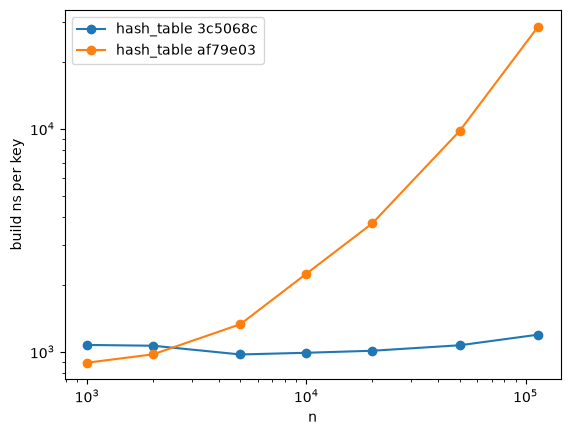

In [15]:
old = df[(df.experiment == "E1_build_memory") & (df.machine_id == "vivian-mbp")
         & (df.index_type == "hash_table")].copy()
fig, ax = plt.subplots()
for ver, g in old.groupby("code_version"):
    med = (g.total_ns / g.n_ops).groupby(g.n_keys).median()
    ax.plot(med.index, med.values, marker="o", label=f"hash_table {ver}")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("n"); ax.set_ylabel("build ns per key"); ax.legend()
plt.show()

In [16]:
#E5 analysis 
e5 = df[(df.experiment == "E5_insert_order") & (df.machine_id == "vivian-mbp")
        & (df.code_version == "65f0ceb")].copy()
print(len(e5), "rows (expect 840)")

for n in (100000,):
    b = e5[(e5.operation == "build") & (e5.n_keys == n)]
    print(f"\nBuild time (ms), n={n:,}")
    print((b.groupby(["index_type", "insert_order"]).total_ns.median() / 1e6).unstack().round(1))
    print(f"\nHeight / rotations / splits (median), n={n:,}")
    print(b.groupby(["index_type", "insert_order"])[["height", "rotations", "splits"]].median().unstack().round(0))

h = e5[(e5.operation == "point_hit") & (e5.n_keys == 100000)]
print("\nLookup ns per op, n=100,000")
print((h.groupby(["index_type", "insert_order"]).total_ns.median() / h.n_ops.iloc[0]).unstack().round(0))

840 rows (expect 840)

Build time (ms), n=100,000
insert_order   nearly_sorted  random  reversed  sorted
index_type                                            
avl_tree               974.5   847.3     844.8   856.9
bplus_tree             272.5   289.7     279.0   256.5
hash_table             166.9   167.9     173.9   180.7
ref_bisect             229.1  1699.8    3333.0    44.1
ref_dict                24.2    23.6      24.3    27.1
sorted_list            384.5  1849.8    3476.7   190.6
unsorted_list           13.4    13.0      14.2    14.9

Height / rotations / splits (median), n=100,000
                     height                            rotations           \
insert_order  nearly_sorted random reversed sorted nearly_sorted   random   
index_type                                                                  
avl_tree               20.0   20.0     17.0   17.0      119947.0  69932.0   
bplus_tree              4.0    4.0      4.0    4.0           0.0      0.0   
hash_table           